# Détection de caractéristiques

Détection de lignes sur la route (lane detection)

* https://www.geeksforgeeks.org/machine-learning/opencv-real-time-road-lane-detection/
  Canny + masque sur le trapèze devant l'image + hough


Détection de panneaux (Traffic Sign Detection)

* https://emanual.robotis.com/docs/en/platform/turtlebot3/autonomous_driving/#autonomous-driving
* SIFT
* https://github.com/hoanglehaithanh/Traffic-Sign-Detection
* https://github.com/mohd-adeeb011/Traffic-Sign-Board-Recognition-Using-Camera

<!-- Panneaux : Grondin, CC BY-SA 3.0 <https://creativecommons.org/licenses/by-sa/3.0>, via Wikimedia Commons -->

In [74]:
import skimage.io as io
import matplotlib.pyplot as plt
import skimage.color as clr
from skimage.feature import canny
import numpy as np
from skimage.transform import hough_line, hough_line_peaks
from numpy import cos, sin, rad2deg
from skimage.feature import match_template
from skimage.transform import resize
from skimage.feature import match_descriptors, plot_matched_features, SIFT
import time
from skimage.transform import resize

## Chargement d'une image de route et prétraitement

La première étape du filtre de Canny est d'appliquer sur l'image un filtre gaussien : pour quelle raison ? : utiliser une image très bruitée

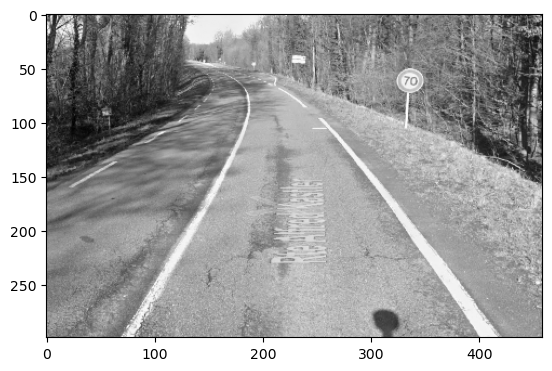

In [135]:
# img = io.imread('460/road2.jpg')
img = io.imread('sv/sv2.png')
img = clr.rgb2gray(img[:,:,:3])
R,C = img.shape
F = C/460
img = resize(img, (R//F,C//F))
plt.imshow(img, "gray")
plt.show()

## Détection de lignes (Canny + masque + Hough)

Détecteur de Canny pour trouver les contours. Je demanderai probablement aux étudiants de jouer avec sigma en comprenant ce que c'est et quelle est son influence.

Deux façons de faire : en multipliant le résultat de Canny par le masque ou en mettant le masque en paramètre d'entrée

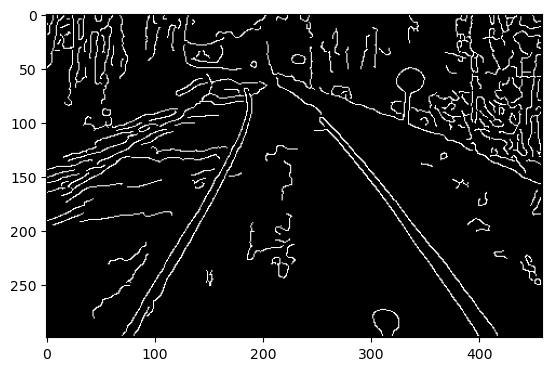

In [136]:
contours = canny(img, sigma=2)
plt.imshow(contours, "gray")
plt.show()

Masque pour ne considérer que les contours qui sont plus ou moins sur la route. Je donnerai le contour comme une image binaire à charger.

299 459


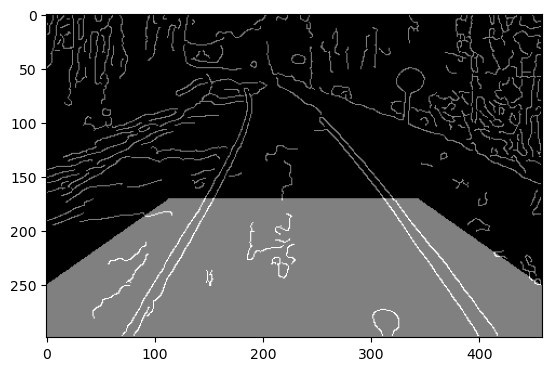

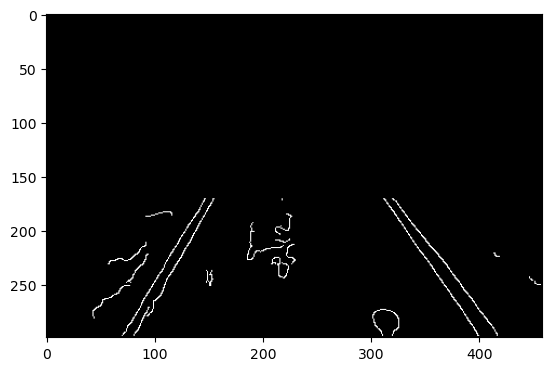

In [137]:
# Masque
R, C = contours.shape
print(R,C)
r = np.arange(R)
c = np.arange(C)
cols, rows = np.meshgrid(c, r)
mask = np.ones((R,C))

# 460
mask = np.where( rows>170, mask, 0 )
mask = np.where( rows<300, mask, 0 )
mask = np.where( rows >  .7 * cols - 70, mask, 0 )
mask = np.where( rows > -.7 * cols + 250, mask, 0 )

# Enregistrement
import skimage as ski
mask_save = ski.util.img_as_ubyte(mask)
io.imsave("route-masque.png", mask_save)

contours_masked = contours * mask

# Affichage
plt.figure()
plt.imshow(mask+contours, "gray")#, origin='lower')
plt.show()
# Affichage
plt.figure()
plt.imshow(contours_masked, "gray")
plt.show()

Transformée de Hough pour trouver les lignes. Je donnerai le code pour l'affichage

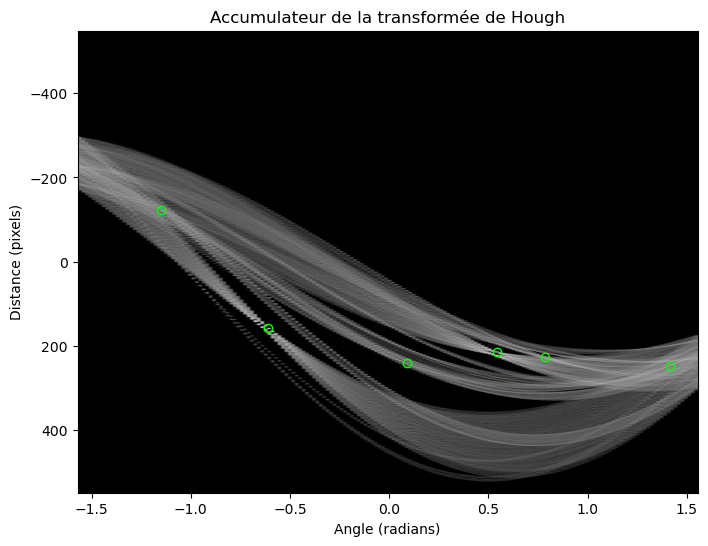

In [138]:
accumulator, angle, dist  = hough_line(contours_masked)
peaks, angles, dists = hough_line_peaks(accumulator, angle, dist, threshold=.1*accumulator.max(), min_distance = 100)

# Affichage
axes = (angle[0], angle[-1], dist[-1], dist[0])
plt.figure(figsize=(8,6))
plt.imshow(np.log(accumulator+1), cmap="gray", extent=axes, aspect="auto")
plt.xlabel('Angle (radians)')
plt.ylabel('Distance (pixels)')
plt.title("Accumulateur de la transformée de Hough")
plt.plot(angles, dists, marker='o', markeredgecolor='lime', markerfacecolor="none", linestyle="none")
plt.show()

Affichage des lignes détectées. Là aussi je donnerai de gros indices pour l'affichage.

redonner la géométrie de theta et dist pour tracer les lignes
faire un filtre pour ne conserver que deux lignes par ex (à partir de la valeur de peaks)

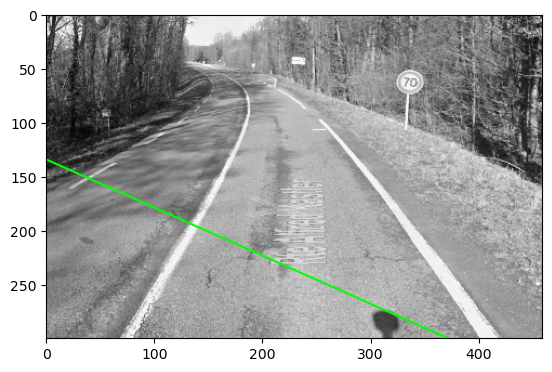

In [139]:
plt.figure
plt.imshow(img, cmap="gray")

for _, angle, dist in zip(peaks, angles, dists):

    # Ne sélectionne que les lignes pas trop horizontales ou pas trop verticale : ce sera aux étudiants de faire ces seuillages
    if np.abs(angle) > .5*np.pi/2 and np.abs(angle) < .8*np.pi/2:
        
        # Coordonnée de la ligne
        x0 = 0
        y0 = dist / sin(angle)
        x1 = C
        y1 = (dist - x1*cos(angle)) / sin(angle)
        
        # Tracé de la ligne
        plt.plot((x0, x1), (y0, y1), color='lime')

plt.axis((0,C,R,0))
plt.show()

[134  95  36  31  26  25]
[1.         0.70895522 0.26865672 0.23134328 0.19402985 0.18656716]


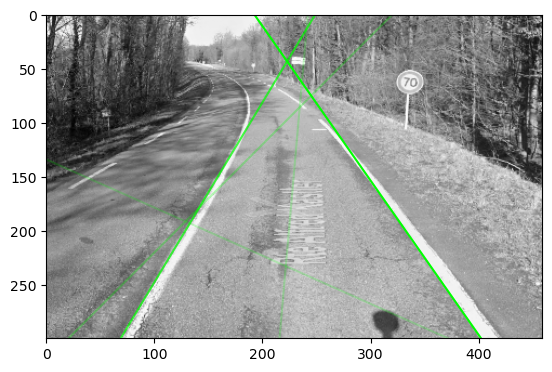

In [140]:
plt.figure
plt.imshow(img, cmap="gray")

P = np.max(peaks)
alphas = peaks/P

print(peaks)
print(alphas)

for k in range(len(peaks)):
    
    angle = angles[k]
    dist = dists[k]
    alpha = alphas[k]

    # Affichage en fonction de l'intensité de peaks mais ne trace pas les lignes trop horizontales
    if alpha > .1 and np.abs(angle) < .8*np.pi/2:
            
        # Coordonnée de la ligne
        x0 = 0
        y0 = dist / sin(angle)
        x1 = C
        y1 = (dist - x1*cos(angle)) / sin(angle)
        
        # Tracé de la ligne
        plt.plot((x0, x1), (y0, y1), color='lime', alpha=alpha)

plt.axis((0,C,R,0))
plt.show()

## Détection de panneaux (filtre adapté vs. SIFT)

L'objectif est de détecter le panneau dans l'image (limitation à 40 ? 90 ? 130 ?)

Dans un premier temps, je demande simplement d'appliquer le filtre adapté pour un panneau.
Puis pour les meilleurs : tester plusieurs motifs (panneaux) et plusieurs tailles, pour mesurer le temps de calcul (et le comparer avec SIFT).
La mesure de la corrélation permet de détecter la vitesse affichée sur le panneau.

Temps de calcul : 79.024 ms
Panneau 50 : meilleure corrélation (0.328) pour une taille 65×65


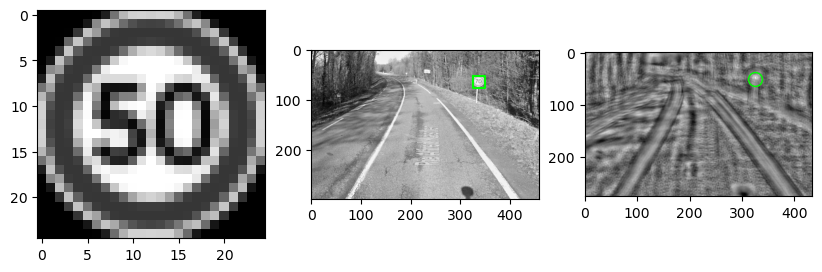

Temps de calcul : 73.564 ms
Panneau 70 : meilleure corrélation (0.305) pour une taille 65×65


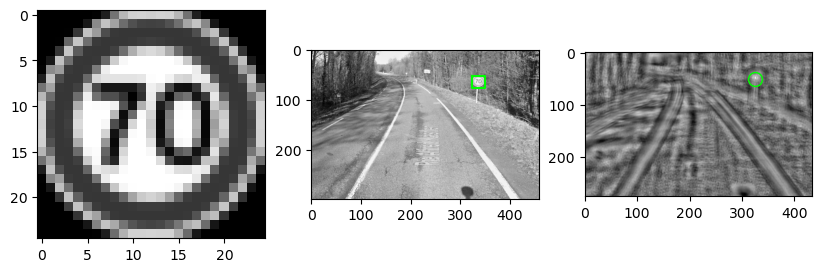

Temps de calcul : 75.085 ms
Panneau 90 : meilleure corrélation (0.287) pour une taille 65×65


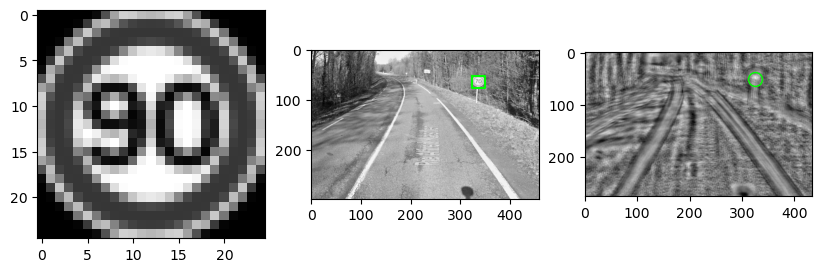

Temps de calcul : 72.549 ms
Panneau 110 : meilleure corrélation (0.369) pour une taille 65×65


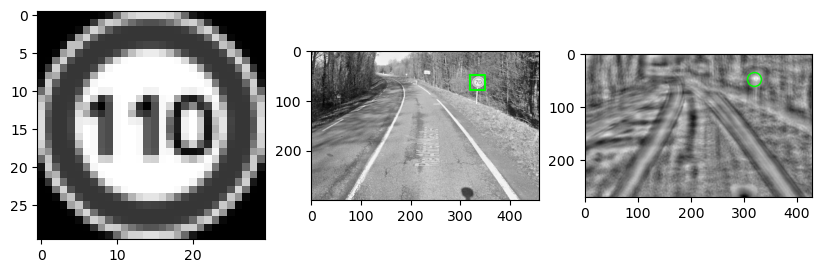

Temps de calcul : 70.298 ms
Panneau 130 : meilleure corrélation (0.366) pour une taille 65×65


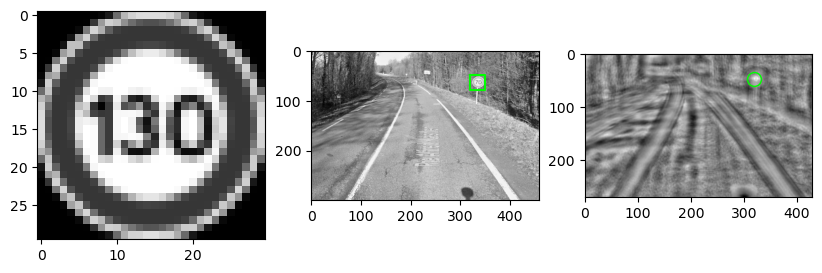

In [143]:
panels = [50, 70, 90, 110, 130]

for P in panels:

    # Panneau
    sign = io.imread(f"P64/P{P}.png")
    sign = clr.rgb2gray(sign[:,:,:3])

    start_time = time.time()
    
    Smax = 0
    result_max = 0
    
    for S in range(20,70,5):
    
        resized = resize(sign, (S,S))
        result = match_template(img, resized)
        
        if np.max(result) > result_max:
            result_max = np.max(result)
            Smax = S
    
    print(f"Temps de calcul : {(time.time()-start_time)*1e3:.3f} ms")

    print(f"Panneau {P} : meilleure corrélation ({np.max(result):.3f}) pour une taille {S}×{S}")
    resized = resize(sign, (Smax,Smax))
    result = match_template(img, resized)
    ij = np.unravel_index(np.argmax(result), result.shape)
    x, y = ij[::-1]

    # Affichage
    hcoin, wcoin = resized.shape
    fig, axs = plt.subplots(1, 3, figsize=(10, 3))
    axs[0].imshow(resized, "gray")
    axs[1].imshow(img, "gray")
    axs[1].plot([x, x+wcoin, x+wcoin, x, x], [y, y, y+hcoin, y+hcoin, y], color='lime')    
    axs[2].imshow(result, "gray")
    axs[2].plot(x, y, 'o', markeredgecolor='lime', markerfacecolor='none', markersize=10)
    plt.show()

Test avec SIFT. Idem, les meilleurs testeront plusieurs panneaux et mesureront le temps de calcul.
Une amélioration dans mon code serait de filtrer les matching pour ne conserver que ceux qui sont issus de la même zone, ceci afin d'identifier le panneau.

Temps de calcul : 11.101 ms


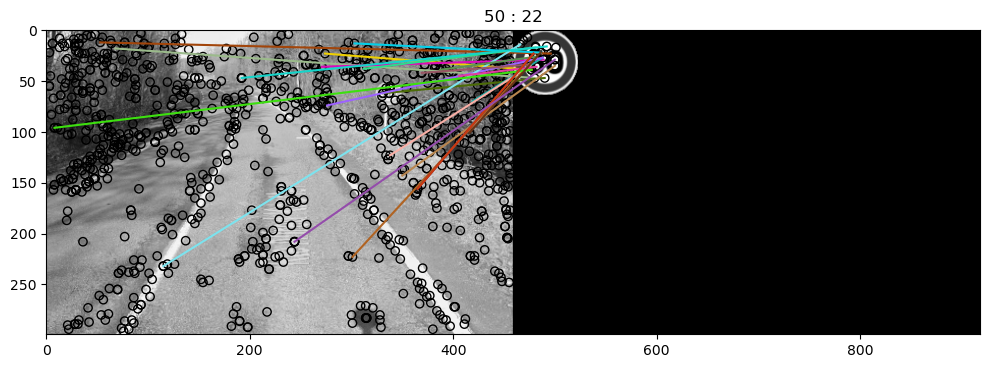

[[  3 416]
 [  3 386]
 [  3  93]
 ...
 [ 62 337]
 [ 67 213]
 [283 315]]
(22, 2)


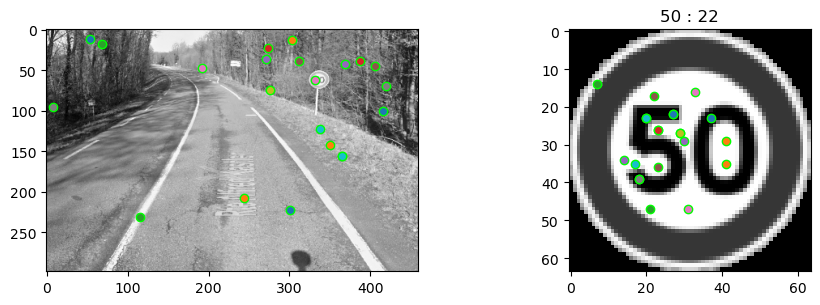

Temps de calcul : 11.021 ms


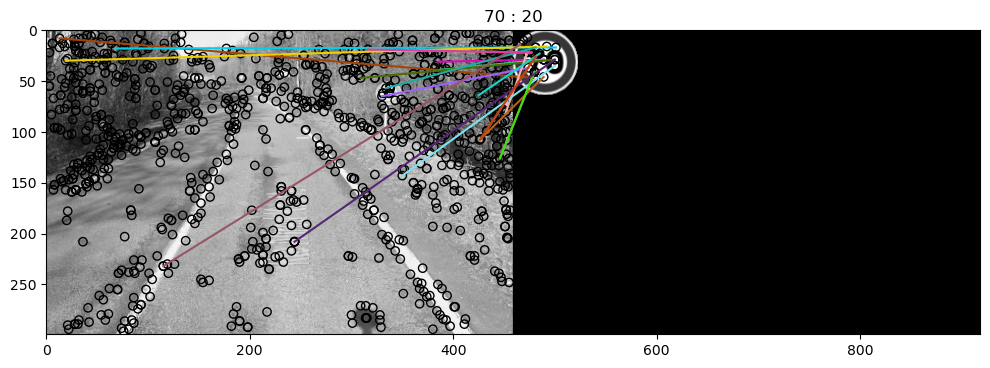

[[  3 416]
 [  3 386]
 [  3  93]
 ...
 [ 62 337]
 [ 67 213]
 [283 315]]
(20, 2)


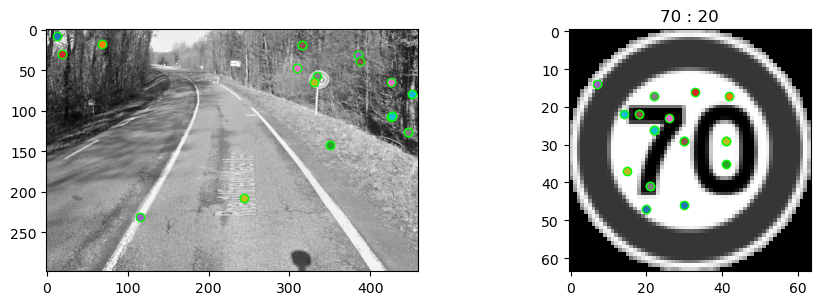

Temps de calcul : 12.059 ms


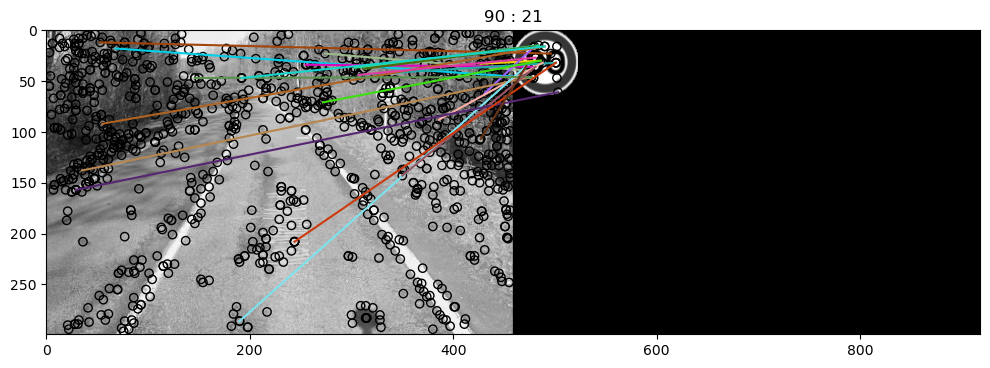

[[  3 416]
 [  3 386]
 [  3  93]
 ...
 [ 62 337]
 [ 67 213]
 [283 315]]
(21, 2)


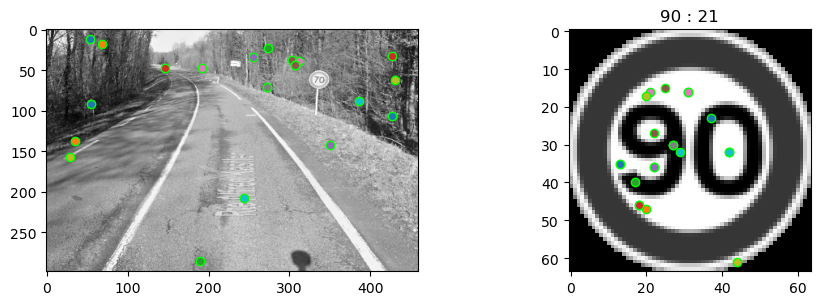

Temps de calcul : 10.828 ms


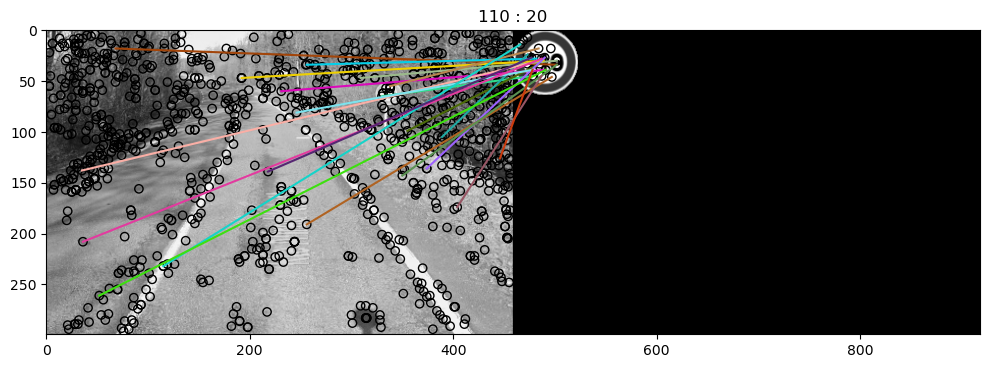

[[  3 416]
 [  3 386]
 [  3  93]
 ...
 [ 62 337]
 [ 67 213]
 [283 315]]
(20, 2)


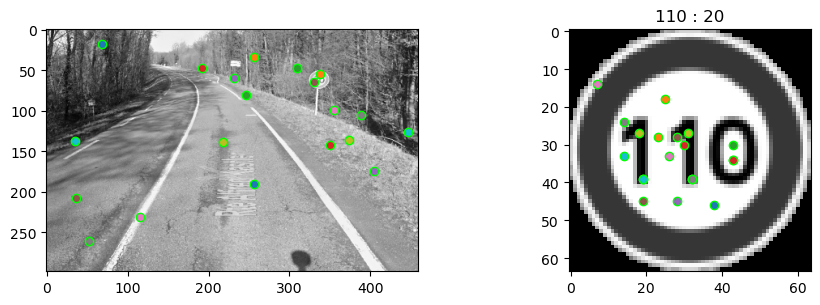

Temps de calcul : 12.940 ms


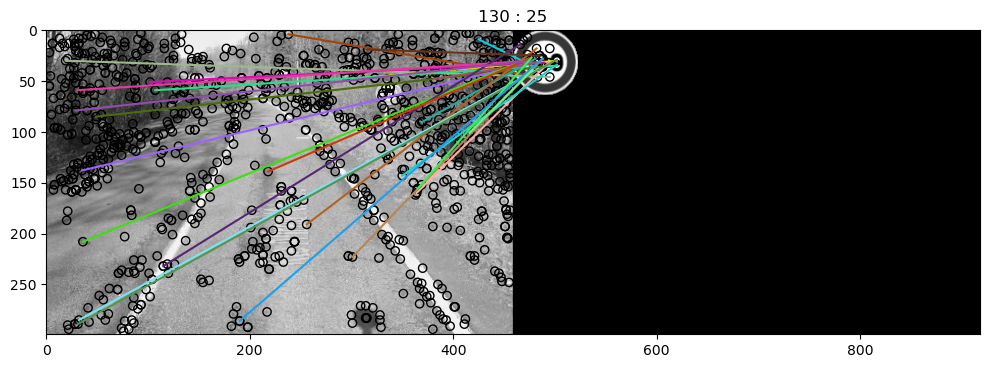

[[  3 416]
 [  3 386]
 [  3  93]
 ...
 [ 62 337]
 [ 67 213]
 [283 315]]
(25, 2)


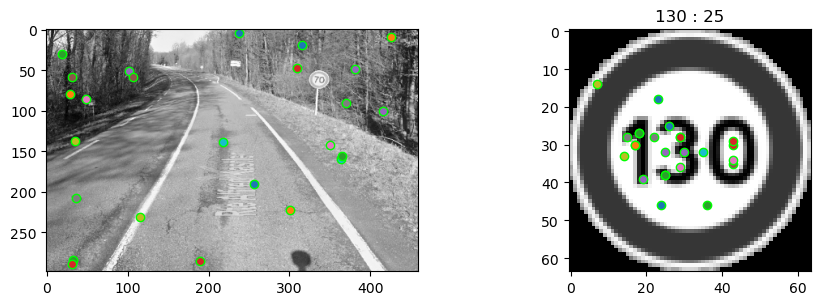

In [142]:
# SIFT sur l'image
descriptor_extractor = SIFT()
descriptor_extractor.detect_and_extract(img)
keypoints0 = descriptor_extractor.keypoints
descriptors0 = descriptor_extractor.descriptors

for P in panels:

    # Panneau
    sign = io.imread(f"P64/P{P}.png")
    sign = clr.rgb2gray(sign[:,:,:3])

    start_time = time.time()

    # SIFT sur le panneau
    descriptor_extractor.detect_and_extract(sign)
    keypoints1 = descriptor_extractor.keypoints
    descriptors1 = descriptor_extractor.descriptors

    # Matching
    matches = match_descriptors(descriptors0, descriptors1)#, max_ratio=.8)
    
    print(f"Temps de calcul : {(time.time()-start_time)*1e3:.3f} ms")

    # Affichage
    plt.figure(figsize=(10, 5))
    plot_matched_features(
        img,
        sign,
        keypoints0=keypoints0,
        keypoints1=keypoints1,
        matches=matches,
        # only_matches = True,
        # matches_color='#0000',
        # keypoints_color='lime',
        ax=plt.gca(),
    )
    plt.tight_layout()
    plt.title(f"{P} : {matches.shape[0]}")
    plt.show()
        
    # Affichage
    fig, axs = plt.subplots(1, 2, figsize=(10, 3))
    axs[0].imshow(img, "gray")
    axs[1].imshow(sign, "gray")

    print(keypoints0)
    print(matches.shape)
    for m in matches[:,0]:
        p = keypoints0[m]
        axs[0].plot(p[1], p[0], marker="o", markeredgecolor="lime")
    for m in matches[:,1]:
        p = keypoints1[m]
        axs[1].plot(p[1], p[0], marker="o", markeredgecolor="lime")
    plt.tight_layout()
    plt.title(f"{P} : {matches.shape[0]}")
    plt.show()